In [46]:
try:
   import cPickle as pickle
except:
   import pickle

In [2]:
import ipyparallel as ipp
import os
import time

c = ipp.Client()

In [3]:
import ipyparallel as ipp
import os
import time

c = ipp.Client()
c[:].use_cloudpickle()
v = c.load_balanced_view()
v.map(os.chdir, [os.getcwd()]*len(c.ids))
#dview = c[:] # use all engines
#dview.use_cloudpickle()
#dview.map(os.chdir, [os.getcwd()]*16)

<AsyncMapResult: chdir>

In [4]:
scenario_name = 'base'

In [5]:
%matplotlib inline
%reload_ext autoreload
%load_ext line_profiler
%run -i deg
%run -i deg_params
%aimport ws3
%aimport deg
%autoreload 2

Compiled interpolation routine not available
Compiled sparse grid routine not available


In [6]:
proc_mode = 'seq_tsa'
deg_mode = 'rhrs' #'classic'
obj_mode = 'max_hvol'
#horizon = 2
run_sda = 1 # set to True for production runs

In [7]:
#basenames = ['tsa01', 'tsa10']

In [8]:
kwargs = []
for i, bn in enumerate(basenames):
    kwargs.append({'basenames':[bn],
                   'model_name':'%s_%s' % (scenario_name, bn),
                   'model_path':dat_path,
                   'yld_path':yld_path,
                   'tif_path':tif_path,
                   'horizon':horizon,
                   'period_length':period_length,
                   'max_age':max_age,
                   'basecodes':compile_basecodes({bn:pickle.load(open('%s/hdt_%s.pkl' % (hdt_path, bn), 'rb'))}, [bn], theme_cols),
                   'action_params':action_params,
                   'hdt':{bn:pickle.load(open('%s/hdt_%s.pkl' % (hdt_path, bn), 'rb'))},
                   'add_null_action':True,
                   'tvy_name':tvy_name,
                   'compile_actions':True,
                   'compile_ogi':True if scenario_name in ['rogh'] else False,
                   'verbose':1,
                   'scenario_name':scenario_name, 
                   'util':util, 
                   'deg_mode':deg_mode,
                   'fm_horizon':2,
                   'sda_mode':sda_mode,
                   'obj_mode':obj_mode,
                   'base_year':base_year,
                   'run_sda':run_sda,
                   'cmp_fm_only':False})

In [9]:
def unpickle_forestmodel(scenario_name, basename):
    return pickle.load(open('../dat/out/%s_%s_fm.pkl' % (scenario_name, basename), 'rb'))

def unpickle_schedule(scenario_name, basename):
    return pickle.load(open('../dat/out/%s_%s_sch.pkl' % (scenario_name, basename), 'rb'))

In [10]:
def deg_diagnostic1(fm, basenames, sch, util=0.85, figsize=(10, 4)):
    import matplotlib.pyplot as plt
    from pandas import DataFrame as DF
    exprs = {'harvest':'totvol * %0.2f' % util, 'fire':'1.'}
    _acodes = 'harvest', 'fire'
    for bn in basenames:
        fig, ax = plt.subplots(figsize=figsize)
        mask = (bn, '?', '?', '?')
        dtype_keys = fm.unmask(mask)
        _area = {_acode:{t:0.  for t in fm.periods} for _acode in _acodes}
        for dtk, age, area, acode, period, etype in sch:
            if dtk in dtype_keys and acode in _acodes:
                _area[acode][period] += area
        d = {'t':[], 'harvest':[], 'fire':[], 
             'acut_ws3':[], 
             'acut_sch':list(_area['harvest'].values())}
        for t in fm.periods:
            d['t'].append(t)
            d['acut_ws3'].append(fm.compile_product(t, '1.', 'harvest', dtype_keys=dtype_keys))
            for acode in _acodes:
                expr = exprs[acode]
                d[acode].append(fm.compile_product(t, expr, acode, dtype_keys=dtype_keys))
        #print(d)
        df = DF(data=d).set_index('t')
        df = df.astype(int)
        df[['acut_ws3', 'acut_sch']].plot.bar(ax=ax)
        print(df)
        
def deg_diagnostic2(fm, basenames, sch, figsize=(10, 10), D=('harvest', 'fire'), period_length=10):
    import matplotlib.pyplot as plt
    from pandas import DataFrame as DF
    fig, ax = plt.subplots(3, 1, figsize=figsize)
    for bn in basenames:
        _sch = [x for x in sch if x[0][0] == bn]
        df = pd.DataFrame(_sch, columns=['themevals', 'age', 'area', 'action', 'period', 'foo'])
        #df = df.query('period <= 6')
        df['period'] = df['period']*period_length - period_length + 1
        df['area'] /= float(period_length)
        sch_area = df.groupby(by=['action', 'period'])['area'].sum()
        sha_area = {d:[0] for d in D}
        for i, d in enumerate(D):
            for j in range(horizon*period_length):
                path = '%s/projected_%s_%i.tif' % (tif_path(bn)[:-4], d, 2015+j)
                with rasterio.open(path) as src:
                    sha_area[d].append(src.read().sum())
        for i, d in enumerate(D):
            if d in sch_area.index:
                sch_area.loc[d].plot(style='o', ax=ax[i], label='Targeted (%s, %s)' % (bn, d))
            ax[i].plot(sha_area[d], '*', label='Scheduled (%s, %s)' % (bn, d))
            ax[i].legend()
            ax[i].set_title('Validation of targeted and scheduled area')
            plt.xlabel('Period (years)')
            plt.ylabel('Area (hectares)')
    for d in D:
        if d in sch_area.index:
            T = [x for x in sch_area.loc[d] for i in range(fm.period_length)]
        S = sha_area[d][1:]
        E = [1.-(s/t) for t, s in zip(T, S)]
        plt.plot(E, 'o', label=d)
    ax[2].set_title('Relative target shortfall')
    ax[2].set_xlabel('Period (years)')
    ax[2].set_ylabel('Proportion of target not scheduled')
    ax[2].legend()
    
    
def deg_diagnostic3(fm, basenames, distname, figsize=(15, 6)):
    import matplotlib.pyplot as plt
    from pandas import DataFrame as DF
    n = 4
    fig, ax = plt.subplots(1, 4, figsize=figsize, sharex=True, sharey=True)
    for ni, bn in enumerate(basenames):
        for j in [0, 1]:
            ax[j].set_yticklabels([])
            ax[j].set_xticklabels([])
            ax[j].set_title('%s %s (%i)' % (bn, distname, 2015+j))
            path = '%s/%s/projected_%s_%i.tif' % (os.path.split(tif_path(bn))[0], bn, distname, 2015+j)
            rasterio.plot.show(rasterio.open(path), ax=ax[j])
        for j in [2, 3]:
            ax[j].set_yticklabels([])
            ax[j].set_xticklabels([])
            year = 2015+horizon-3+(j-1)
            ax[j].set_title('%s %s (%i)' % (bn, distname, year))
            path = '%s/%s/projected_%s_%i.tif' % (os.path.split(tif_path(bn))[0], bn, distname, year)
            rasterio.plot.show(rasterio.open(path), ax=ax[j])
    plt.tight_layout()
    

In [11]:
def do_the_thing(basenames, model_name, model_path, yld_path, tif_path, horizon, period_length,
                 max_age, basecodes, action_params, hdt, add_null_action, tvy_name, compile_actions,
                 compile_ogi, verbose, scenario_name, util, deg_mode, fm_horizon, sda_mode, obj_mode,
                 base_year, fm=None, run_sda=True, cmp_fm_only=False):
    from deg import bootstrap_forestmodel, pickle_forestmodel, pickle_schedule
    try:
        fm = bootstrap_forestmodel(basenames=basenames, 
                                   model_name=model_name, 
                                   model_path=model_path, 
                                   yld_path=yld_path, 
                                   tif_path=tif_path, 
                                   horizon=horizon,
                                   period_length=period_length, 
                                   max_age=max_age, 
                                   basecodes=basecodes, 
                                   action_params=action_params, 
                                   hdt=hdt, 
                                   add_null_action=add_null_action,
                                   tvy_name=tvy_name, 
                                   compile_actions=compile_actions, 
                                   compile_ogi=compile_ogi, 
                                   verbose=verbose)
        pickle_forestmodel(fm, scenario_name, basenames[0])
        if cmp_fm_only:
            return 0
        sch = run_deg(fm=fm, 
                      basenames=basenames, 
                      scenario_name=scenario_name, 
                      util=util, 
                      tif_path=tif_path, 
                      hdt=hdt, 
                      horizon=horizon, 
                      deg_mode=deg_mode, 
                      fm_horizon=fm_horizon, 
                      sda_mode=sda_mode, 
                      obj_mode=obj_mode)
        pickle_schedule(sch, scenario_name, basenames[0])
        if run_sda:
            sda(fm=fm, 
                basenames=basenames, 
                base_year=base_year, 
                period_length=period_length, 
                horizon=horizon, 
                tif_path=tif_path, 
                hdt=hdt, 
                sda_mode=sda_mode)
        zip_output(basenames, scenario_name)
        return 0
    except Exception as e:
        return e


In [12]:
def do_the_thing2(basenames):
        if clean_inv: clean_inventory()
        if rasterize_inv: rasterize_inventory(basenames, shp_path, tif_path, hdt_path, theme_cols, age_col, period_length)
        hdt = {bn:pickle.load(open('%s/hdt_%s.pkl' % (hdt_path, bn), 'rb')) for bn in basenames}
        basecodes = compile_basecodes(hdt, basenames, theme_cols)
        compile_ogi = True if scenario_name in ['rogh'] else False
        fm = bootstrap_forestmodel(basenames,
                                   model_name='foo',
                                   model_path=dat_path,
                                   yld_path=yld_path,
                                   tif_path=tif_path,
                                   horizon=horizon,
                                   period_length=period_length,
                                   max_age=max_age,
                                   basecodes=basecodes,
                                   action_params=action_params,
                                   hdt=hdt,
                                   add_null_action=True,
                                   tvy_name=tvy_name,
                                   compile_actions=True,
                                   compile_ogi=compile_ogi,
                                   verbose=1)
        sch = run_deg(fm, basenames, scenario_name, util, tif_path, hdt, horizon, deg_mode=deg_mode, obj_mode=obj_mode)
        sda(fm, basenames, base_year, period_length, horizon, tif_path, hdt, sda_mode=sda_mode)
        deg_diagnostic1(fm, basenames, sch, util)
        deg_diagnostic2(fm, basenames, sch, figsize=(10, 10))
        return fm, sch
        #for distname in ['harvest', 'fire']:
        #    deg_diagnostic3(fm, basenames, distname)
        #zip_output(basenames, scenario_name)     - comment out April 9, 2018

In [13]:
#basenames, model_name, model_path, yld_path, tif_path, horizon, period_length, max_age, 

In [14]:
result = do_the_thing(**kwargs[1])

instantiating ForestModel object
bootstrap_themes
bootstrap_areas
<function <lambda> at 0x7fb5f03fa9d8>
bootstrap_yields
bootstrap_actions
adding null actions
compiling actions
finalizing ForestModel config
Running iteration 0
base
Optimize a model with 2048 rows, 3359 columns and 9903 nonzeros
Coefficient statistics:
  Matrix range     [1e-01, 8e+06]
  Objective range  [2e-01, 8e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 7e+06]
Presolve removed 1404 rows and 2042 columns
Presolve time: 0.01s
Presolved: 644 rows, 1319 columns, 5227 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    6.6250187e+07   4.012025e+03   0.000000e+00      0s
     632    1.3522942e+07   0.000000e+00   0.000000e+00      0s

Solved in 632 iterations and 0.03 seconds
Optimal objective  1.352294200e+07
foo

Running iteration 1
base
Optimize a model with 1888 rows, 2631 columns and 6355 nonzeros
Coefficient statistics:
  Matrix range     [1e-01, 8e+06]
  Objec

In [23]:
amr = v.map_async(lambda kwargs: do_the_thing(**kwargs), kwargs)

In [24]:
amr.wait_interactive()

   0/2 tasks finished after  792 s

KeyboardInterrupt: 

In [13]:
amr_fm = [unpickle_forestmodel(scenario_name, bn) for bn in basenames]

In [14]:
amr_sch = [unpickle_schedule(scenario_name, bn) for bn in basenames]

In [25]:
outfile = open('../dat/out/distout_vcut.csv', 'w')
outfile.write('SCENARIO,TSA,PERIOD,VCUT,ABRN\n')
for i, bn in enumerate(basenames[:]):
    print(i, bn)
    fm, sch = amr_fm[i], amr_sch[i]
    fm.reset_actions()
    fm.initialize_areas()
    fm.apply_schedule(sch, compile_c_ycomps=True)
    for j in range(1, horizon+1):
        vcut = fm.compile_product(j, 'totvol * %0.2f' % util, acode='harvest')
        abrn = fm.compile_product(j, '1.', acode='fire')
        outfile.write('%s,%s,%i,%i,%i\n' % (scenario_name, bn, j, int(vcut), int(abrn)))
outfile.close()

0 tsa01
1 tsa02
2 tsa03
3 tsa04
4 tsa05
5 tsa07
6 tsa08
7 tsa09
8 tsa10
9 tsa11
10 tsa12
11 tsa13
12 tsa14
13 tsa15
14 tsa16
15 tsa17
16 tsa18
17 tsa19
18 tsa20
19 tsa21
apply action error 1 ('tsa21', '1', '178', 'redcedar') harvest 1 78 0.0
apply action error 1 ('tsa21', '1', '181', 'redcedar') harvest 1 9 0.0
apply action error 1 ('tsa21', '1', '202', 'western_hemlock') harvest 1 53 0.0
apply action error 1 ('tsa21', '1', '201', 'western_hemlock') harvest 1 63 0.0
apply action error 1 ('tsa21', '1', '248', 'cypress') harvest 1 66 0.0
apply action error 1 ('tsa21', '1', '233', 'sitka_spruce') harvest 1 54 0.0
apply action error 1 ('tsa21', '1', '170', 'amabilis_fir') harvest 1 49 0.0
apply action error 1 ('tsa21', '1', '536', 'mountain_hemlock') harvest 1 48 0.0
apply action error 1 ('tsa21', '1', '225', 'spruce') harvest 1 48 0.0
apply action error 1 ('tsa21', '1', '183', 'red_alder') harvest 1 8 0.0
apply action error 1 ('tsa21', '1', '171', 'amabilis_fir') harvest 1 44 0.0
apply ac

In [16]:
import zipfile
scenarionames = ['base'] #, 'more', 'rogh']
outfile = open('../dat/out/distout_area.csv', 'w')
outfile.write('SCENARIO,TSA,DISTURB,YEAR,AREA\n')
for sn in scenarionames:
    for bn in basenames:
        with zipfile.ZipFile('../dat/out/%s/%s_%s_distout.zip' % (sn, sn, bn), 'r') as zf:
            zf.extractall('../dat/out/%s' % sn)
        for dn in ['fire', 'harvest', 'slashburn']:
            for dy in range(60):
                yr = 2015 + dy
                with rasterio.open('../dat/out/%s/%s/projected_%s_%i.tif' % (sn, bn, dn, yr)) as src:
                    n = src.read()[0].sum()
                #print(sn, bn, dn, yr, n)
                outfile.write('%s,%s,%s,%i,%i\n' % (sn, bn, dn, yr, n))
outfile.close()                                

0 tsa01
   acut_sch  acut_ws3  fire  harvest
t                                   
1     58496     58496  6753  7970835
2     51426     51426  6753  7968418


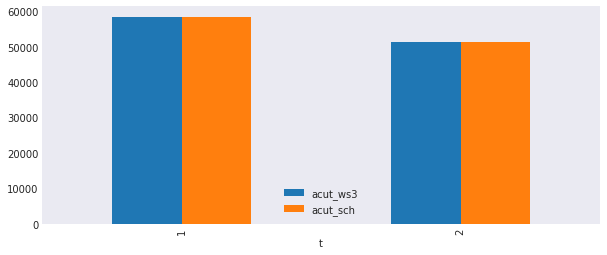

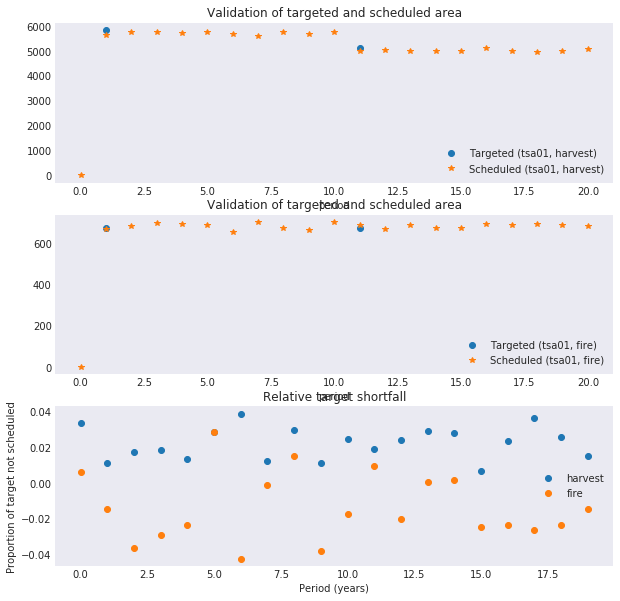

In [44]:
for i, bn in enumerate(basenames):
    print(i, bn)
    fm, sch = amr_fm[i], amr_sch[i]
    fm.reset_actions()
    fm.initialize_areas()
    fm.apply_schedule(sch, compile_c_ycomps=True)
    deg_diagnostic1(fm, [bn], sch, util)
    deg_diagnostic2(fm, [bn], sch, figsize=(10, 10))

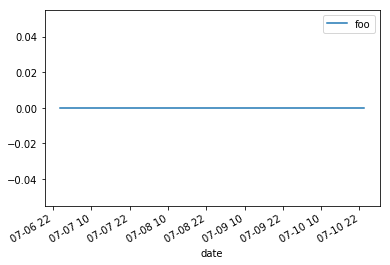

In [45]:
import io
import pandas as pd
output = !(ls -la --time-style='long-iso' ../dat/out/base*distout.zip)
output = [' '.join(r.split()[5:7]) for r in output]
df = pd.DataFrame(output, columns=['date'])
df['date'] = pd.to_datetime(df.date, infer_datetime_format=True)
df['foo'] = 0
df = df.set_index('date')
df.plot()
#output
#df = pd.read_table(io.StringIO(output.n), header=None)

In [5]:
df

,0
0,-rw-r--r-- 1 gparadis gparadis 2149969 Jul 10...
1,-rw-r--r-- 1 gparadis gparadis 1410277 Jul 9...
2,-rw-r--r-- 1 gparadis gparadis 1515588 Jul 9...
3,-rw-r--r-- 1 gparadis gparadis 5172369 Jul 9...
4,-rw-r--r-- 1 gparadis gparadis 2462987 Jul 9...
5,-rw-r--r-- 1 gparadis gparadis 1756623 Jul 9...
6,-rw-r--r-- 1 gparadis gparadis 7401421 Jul 9...
7,-rw-r--r-- 1 gparadis gparadis 2284650 Jul 9...
8,-rw-r--r-- 1 gparadis gparadis 1115426 Jul 10...
9,-rw-r--r-- 1 gparadis gparadis 5639757 Jul 7...
